In [3]:
import os
import sys
from pathlib import Path

REPO_PATH = Path("/content/Generative-Models-Comparation")
if REPO_PATH.exists():
    os.chdir(REPO_PATH)

ROOT_DIR = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import torch
import matplotlib.pyplot as plt
from src.config import Config
from src.utils.seed import set_seed
from src.utils.io_helpers import save_checkpoint, save_json
from src.dataset import get_dataloaders
from src.models.ddpm import SmallUNet, DDPM
from src.trainers.train_ddpm import train_ddpm
from src.evaluation.metrics import measure_inference_latency_ms

set_seed(Config.SEED)
Config.ensure_dirs()
print(f"Training DDPM on device: {Config.DEVICE}")

train_loader, val_loader, _ = get_dataloaders(
    batch_size=Config.BATCH_SIZE,
    seed=Config.SEED,
    num_workers=2 if torch.cuda.is_available() else 0,
)

unet = SmallUNet(
    img_channels=Config.IMG_CHANNELS,
    base_channels=Config.DDPM_BASE_CHANNELS,
    time_dim=128,
)
ddpm = DDPM(
    unet=unet,
    timesteps=Config.DDPM_TIMESTEPS,
    beta_start=Config.DDPM_BETA_START,
    beta_end=Config.DDPM_BETA_END,
)

train_out = train_ddpm(
    model=ddpm,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=Config.DDPM_EPOCHS,
    lr=Config.DDPM_LR,
    device=Config.DEVICE,
)

ddpm.eval()
latency_ms = measure_inference_latency_ms(
    forward_fn=lambda: ddpm.sample(64, Config.DEVICE),
    device=Config.DEVICE,
    warmup_runs=1,
    timed_runs=5,
)
print(f"DDPM Full Reverse Sampling Latency (batch=64, T=1000): {latency_ms} ms")

save_checkpoint(ddpm, Config.CHECKPOINT_DIR / "ddpm.pth")
save_json(
    {
        "model": "Denoising Diffusion Probabilistic Model (DDPM)",
        "latent_dim": "28x28 (Image Space)",
        "timesteps": Config.DDPM_TIMESTEPS,
        "avg_epoch_time_sec": train_out["avg_epoch_time_sec"],
        "inference_latency_ms_batch64": latency_ms,
        "history": train_out["history"],
    },
    Config.METRICS_DIR / "ddpm_results.json",
)

Training DDPM on device: cuda


100%|██████████| 26.4M/26.4M [00:01<00:00, 19.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 304kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.59MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 26.7MB/s]


[DDPM] Epoch 01/30 | Train Noise MSE: 0.090410 | Val Noise MSE: 0.057261 | Time: 42.89s
[DDPM] Epoch 05/30 | Train Noise MSE: 0.043730 | Val Noise MSE: 0.044430 | Time: 44.30s
[DDPM] Epoch 10/30 | Train Noise MSE: 0.040142 | Val Noise MSE: 0.041197 | Time: 44.32s
[DDPM] Epoch 15/30 | Train Noise MSE: 0.038934 | Val Noise MSE: 0.040518 | Time: 44.39s
[DDPM] Epoch 20/30 | Train Noise MSE: 0.038512 | Val Noise MSE: 0.038230 | Time: 45.07s
[DDPM] Epoch 25/30 | Train Noise MSE: 0.036960 | Val Noise MSE: 0.036875 | Time: 44.79s
[DDPM] Epoch 30/30 | Train Noise MSE: 0.037121 | Val Noise MSE: 0.037530 | Time: 44.87s
DDPM Full Reverse Sampling Latency (batch=64, T=1000): 16435.8387 ms


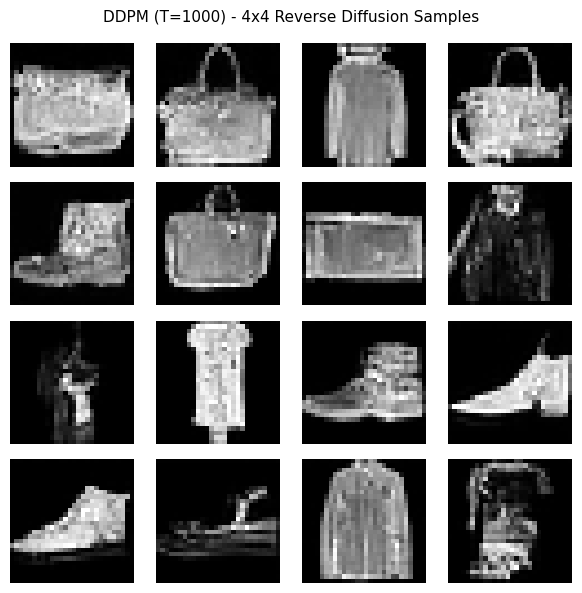

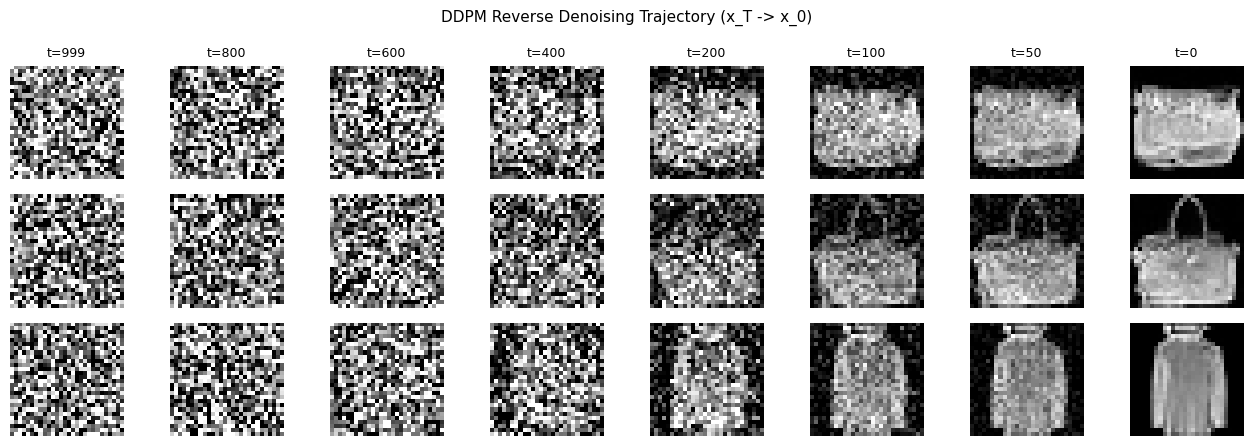

In [4]:
capture_steps = [999, 800, 600, 400, 200, 100, 50, 0]
samples, snapshots = ddpm.sample_with_trajectory(
    num_samples=16,
    device=Config.DEVICE,
    capture_steps=capture_steps,
)
torch.save(snapshots, Config.METRICS_DIR / "ddpm_trajectory_snapshots.pt")

# 4x4 Generated Grid
fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(samples[i].cpu().squeeze(), cmap="gray")
    ax.axis("off")
plt.suptitle("DDPM (T=1000) - 4x4 Reverse Diffusion Samples", fontsize=11)
plt.tight_layout()
plt.show()

# Step-by-step Reverse Denoising Trajectory (first 3 samples)
fig2, axes2 = plt.subplots(3, len(capture_steps), figsize=(13, 4.5))
for r in range(3):
    for c, step in enumerate(capture_steps):
        axes2[r, c].imshow(snapshots[step][r].squeeze(), cmap="gray")
        axes2[r, c].axis("off")
        if r == 0:
            axes2[r, c].set_title(f"t={step}", fontsize=9)
plt.suptitle("DDPM Reverse Denoising Trajectory (x_T -> x_0)", fontsize=11)
plt.tight_layout()
plt.show()